# SpaceX Data Wrangling, EDA and SQL

In [6]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())
display(df.isna().sum())


Dataset shape: (90, 18)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


,0
FlightNumber,0
Date,0
BoosterVersion,0
PayloadMass,0
Orbit,0
LaunchSite,0
Outcome,0
Flights,0
GridFins,0
Reused,0


,count,mean
LaunchSite,,
CCAFS SLC 40,55,0.600000
KSC LC 39A,22,0.772727
VAFB SLC 4E,13,0.769231


,count,mean
Orbit,,
ES-L1,1,1.000000
GEO,1,1.000000
GTO,27,0.518519
HEO,1,1.000000
ISS,21,0.619048
LEO,7,0.714286
MEO,3,0.666667
PO,9,0.666667
SO,1,0.000000


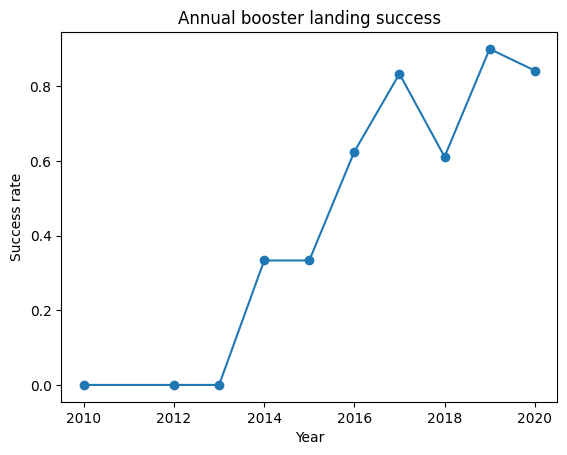

In [7]:
display(df.groupby("LaunchSite").Class.agg(["count","mean"]))
display(df.groupby("Orbit").Class.agg(["count","mean"]))
df.assign(Year=pd.to_datetime(df.Date).dt.year).groupby("Year").Class.mean().plot(marker="o",title="Annual booster landing success");plt.ylabel("Success rate");plt.show()

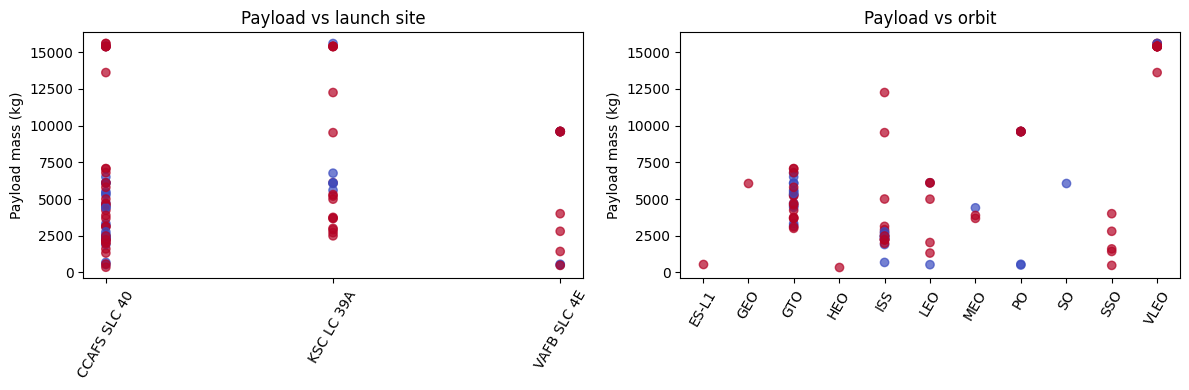

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,(name,col) in zip(axes,[("Payload vs launch site","LaunchSite"),("Payload vs orbit","Orbit")]):
 for k,g in df.groupby(col):ax.scatter([k]*len(g),g.PayloadMass,c=g.Class,cmap="coolwarm",vmin=0,vmax=1,alpha=.7)
 ax.set_title(name);ax.set_ylabel("Payload mass (kg)");ax.tick_params(axis="x",rotation=60)
plt.tight_layout();plt.show()

In [9]:
con=sqlite3.connect(":memory:");df.to_sql("SPACEXTBL",con,index=False)
for q in ["SELECT DISTINCT LaunchSite FROM SPACEXTBL", "SELECT LaunchSite,COUNT(*) AS launches,AVG(Class) AS success_rate FROM SPACEXTBL GROUP BY LaunchSite", "SELECT Orbit,COUNT(*) AS launches,AVG(Class) AS success_rate FROM SPACEXTBL GROUP BY Orbit", "SELECT SUM(PayloadMass) AS total_payload_kg FROM SPACEXTBL"]:
 print(q);display(pd.read_sql_query(q,con))

SELECT DISTINCT LaunchSite FROM SPACEXTBL


,LaunchSite
0,CCAFS SLC 40
1,VAFB SLC 4E
2,KSC LC 39A


SELECT LaunchSite,COUNT(*) AS launches,AVG(Class) AS success_rate FROM SPACEXTBL GROUP BY LaunchSite


,LaunchSite,launches,success_rate
0,CCAFS SLC 40,55,0.600000
1,KSC LC 39A,22,0.772727
2,VAFB SLC 4E,13,0.769231


SELECT Orbit,COUNT(*) AS launches,AVG(Class) AS success_rate FROM SPACEXTBL GROUP BY Orbit


,Orbit,launches,success_rate
0,ES-L1,1,1.000000
1,GEO,1,1.000000
2,GTO,27,0.518519
3,HEO,1,1.000000
4,ISS,21,0.619048
5,LEO,7,0.714286
6,MEO,3,0.666667
7,PO,9,0.666667
8,SO,1,0.000000
9,SSO,5,1.000000


SELECT SUM(PayloadMass) AS total_payload_kg FROM SPACEXTBL


,total_payload_kg
0,549446.347059
